## Heatmap of group differences (iNPH vs controls)
Edit **Cell 1 only** for day-to-day use. Cells 2-5 define the functions; Cell 6 runs everything.

**Expected file format** (one CSV per metric): one row per region, with at least a region name, a raw p-value and an effect size. Other columns (U, n, CI...) are allowed and are carried through untouched.

In [76]:
# CELL 1 - imports and settings you will edit most often
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

# ---- 1. Your input files: one file per metric ----------------
# Key   = the label shown on the heatmap column (keep it short)
# Value = path to that metric's results file
# Order here = left-to-right order on the plot.
# (Edit the paths; add or remove metrics freely.)
FILES = {
    "FA": "/mnt/1248/open/finley/hydrocephalus/heatmap_inputs/1_fa.csv",
    "MD": "/mnt/1248/open/finley/hydrocephalus/heatmap_inputs/1_md.csv",
    "AD": "/mnt/1248/open/finley/hydrocephalus/heatmap_inputs/1_ad.csv",
    "RD": "/mnt/1248/open/finley/hydrocephalus/heatmap_inputs/1_rd.csv",
    "VOL": "/mnt/1248/open/finley/hydrocephalus/heatmap_inputs/1_vol.csv",
    # "NUMBER OF TRACTS": "/mnt/1248/open/finley/hydrocephalus/heatmap_inputs/1_number of tracts.csv",
}

# ---- 2. Optional metric groups (not used with DTI only) ------
# Leave as None: no separators or group titles on the plot.
# Only fill it in if you later want grouped columns, e.g. {"FA": "DTI", "QA": "QSDR"}
METRIC_GROUPS = None

# ---- 3. What the columns in your files are called ------------
# Left side = name used inside this code. Right side = name in your CSV.
# If you rename a column in your files later, change it only here.
COLUMN_MAP = {
    "region": "Regions",
    "p":      "p",       # raw p-value
    "effect": "r",       # effect size (rank-biserial, + = higher in iNPH)
    "failed": None,      # OPTIONAL: CSV column that is True/1 when tractography failed
                         # for that region. Leave None if you don't have one.
    "n_inph": "n_patients",      # OPTIONAL: CSV column with the number of iNPH patients that
                         # went into that test (used for the low-n rule AND the n labels).
    "n_control": "n_controls",   # OPTIONAL: same for controls (only used for the n labels).
}
# Cell status (decided per region and metric):
#   "no data" = region missing from that metric's file, empty p / effect, or flagged in the
#               "failed" column above                -> filled with no_data_color (no marker)
#   "low n"   = data exist, but the group sizes are too small (LOW_N_RULE below)
#                                                       -> normal color from the result + marker
#   otherwise = normal colored cell (with stars if significant)

# How to decide that a cell has "too few samples":
#   "min_p"  = statistical rule (recommended). The smallest p-value an exact Mann-Whitney U test
#              can even produce for these two group sizes is 2 / C(n_inph + n_control, n_inph).
#              If that is larger than 0.05 / (number of tests in the family), the cell could never
#              reach significance, even as the strongest result. Needs BOTH n columns mapped above.
#   "fixed"  = n_inph < MIN_N_INPH (a hard cut-off you choose yourself)
#   "either" = flagged if either rule says so
#   None     = no low-n rule
LOW_N_RULE = "min_p"
MIN_N_INPH = None        # only used by "fixed" / "either"; choose your own value
# A region counts as "no data" for a metric if ANY of these is true:
#   - the region is missing from that metric's file (but present in another file)
#   - its p-value or effect size is empty / NaN
#   - the optional "failed" column above says so

# ---- 4. Multiple-comparison correction -----------------------
FDR_SCOPE = "metric"   # "metric" = each metric its own family (your current plan)
                       # "all"    = one family for everything (strictest)
                       # ("group" also exists, but needs METRIC_GROUPS)
Q_THRESHOLD = 0.05

### Colors
All appearance colors live here. Cell 6 reads this dictionary, so you don't need to touch the plotting call.

In [77]:
# CELL 1B - colors (edit only this cell to restyle the heatmap)
COLORS = dict(
    # Main color scale. Use a matplotlib name ("RdBu_r", "coolwarm", "PuOr_r"...),
    # or your own list of colors from low to high, e.g. ["#2166ac", "white", "#b2182b"]
    cmap="RdBu_r",#["#1474a1", "#fbf5ff", "#921313"],

    # Color scale runs from -vlim to +vlim (rank-biserial r is bounded by 1)
    vlim=1.0,

    # Cells with NO DATA at all are filled with this color
    no_data_color="#eeedcd",

    # Cells that HAVE data but too few iNPH patients keep their normal result color
    # and get this symbol instead of stars; None = no symbol
    low_n_marker="×",
    low_n_marker_color="#555555",

    # The extra "n" columns on the right (number of iNPH patients / controls per region).
    # Use a different, neutral palette so they don't look like part of the heatmap.
    n_cmap="Greys",
    n_text_color="#333333",
    n_low_color="#b2182b",      # iNPH n below MIN_N_INPH is written in this color (bold)

    # Thin lines between cells
    grid_color="white",

    # Significance stars: (color on light cells, color on dark cells)
    star_colors=("black", "white"),
)

### Display options
Which blocks, legend, n columns and failures to show. Cell 6 reads this dictionary.

In [78]:
# CELL 1C - display options (edit only this cell to change WHAT is shown)
DISPLAY = dict(
    # Which heatmap blocks to draw: None = all three, or pick any of
    # "Corpus callosum", "Left", "Right"  e.g. ("Left", "Right") or ("Corpus callosum",)
    panels=None,

    # Colorbar + key for stars, n columns and failed cells
    show_legend=True,

    # Grey columns with n iNPH / n controls (needs n columns mapped in COLUMN_MAP)
    show_n=True,

    # False = hide rows where EVERY metric failed (no data or too few samples)
    show_failed_rows=False,

    # True = hide rows with no significant result in any metric
    only_significant=False,

    # e.g. "QA" = order rows by that metric's effect size; None = file order
    sort_by=None,
)

### Step 1 - read the files
One function reads a single file and renames its columns to standard names; the second stacks all metrics into one long table.

In [79]:
# CELL 2 - STEP 1: read the files
def load_metric_file(path, label, column_map=COLUMN_MAP):
    """Read ONE results file and return a tidy table with standard column names.

    Any extra columns in the file (e.g. U, CI limits) are kept as-is, so you can
    add them to your files later without touching this function.
    """
    df = pd.read_csv(path)
    optional_keys = ("failed", "n_inph", "n_control")

    required = {std: csv for std, csv in column_map.items() if std not in optional_keys}
    missing = [csv for csv in required.values() if csv not in df.columns]
    if missing:
        raise KeyError(
            f"{path}: missing column(s) {missing}. "
            f"Columns found: {list(df.columns)}. Fix COLUMN_MAP in Cell 1."
        )

    # optional columns: use them if mapped AND present, otherwise skip with a warning
    optional = {}
    for std in optional_keys:
        csv = column_map.get(std)
        if not csv:
            continue
        if csv in df.columns:
            optional[std] = csv
        else:
            print(f"Warning: {path} has no column '{csv}' (for '{std}'); skipping it.")

    # rename CSV names -> standard names (region / p / effect / n_inph / n_control / failed)
    df = df.rename(columns={csv: std for std, csv in {**required, **optional}.items()})
    df["failed"] = df["failed"].astype(bool) if "failed" in df.columns else False
    df.insert(0, "metric", label)
    return df


def complete_grid(df):
    """Make sure EVERY region has a row for EVERY metric, and flag failures.

    A region missing from one metric's file (or with an empty p / effect)
    becomes a row with failed=True and NaN values, so it can be drawn.
    """
    if df.duplicated(["metric", "region"]).any():
        dup = df[df.duplicated(["metric", "region"])][["metric", "region"]].head()
        raise ValueError(f"Region listed twice in the same file:\n{dup}")

    regions = list(dict.fromkeys(df["region"]))
    metrics = list(dict.fromkeys(df["metric"]))
    full = pd.MultiIndex.from_product([metrics, regions], names=["metric", "region"])
    df = df.set_index(["metric", "region"]).reindex(full).reset_index()

    df["failed"] = df["failed"].fillna(True).astype(bool)        # absent row -> failed
    df["failed"] |= df["p"].isna() | df["effect"].isna()          # empty values -> failed
    df.loc[df["failed"], ["p", "effect"]] = np.nan                # failed cells carry no value
    return df


def min_possible_p(n1, n2):
    """Smallest two-sided p-value an exact Mann-Whitney U test can give for group sizes n1, n2
    (assuming no ties; with ties it is slightly larger)."""
    return min(1.0, 2.0 / comb(int(n1) + int(n2), int(n1)))


def add_status(df):
    """Label every cell 'ok', 'no_data' or 'low_n'. Run it AFTER add_fdr (it needs the test families)."""
    df = df.copy()
    ok = ~df["failed"]
    df["status"] = np.where(ok, "ok", "no_data")
    low = pd.Series(False, index=df.index)

    if LOW_N_RULE in ("fixed", "either") and MIN_N_INPH:
        if "n_inph" in df.columns:
            low |= ok & (df["n_inph"] < MIN_N_INPH)
        else:
            print("Note: 'fixed' low-n rule needs n_inph in COLUMN_MAP; not applied.")

    if LOW_N_RULE in ("min_p", "either"):
        if {"n_inph", "n_control"} <= set(df.columns):
            m = df.groupby("family")["p"].transform("count")          # number of tests in the family
            has_n = ok & df["n_inph"].notna() & df["n_control"].notna()
            p_min = pd.Series(np.nan, index=df.index)
            p_min[has_n] = [min_possible_p(a, b) for a, b in
                            zip(df.loc[has_n, "n_inph"], df.loc[has_n, "n_control"])]
            df["p_min"] = p_min                                       # kept for the supplementary table
            low |= has_n & (p_min > Q_THRESHOLD / m)
        else:
            print("Note: 'min_p' low-n rule needs n_inph AND n_control in COLUMN_MAP; not applied.")

    df.loc[low, "status"] = "low_n"
    return df


def load_all_metrics(files=FILES):
    """Read every file in FILES and stack them into one long table."""
    tables = [load_metric_file(path, label) for label, path in files.items()]
    return complete_grid(pd.concat(tables, ignore_index=True))


def failed_summary(df):
    """Per metric: how many regions have no data / too few iNPH patients (sanity check)."""
    return df.groupby("metric", sort=False)["status"].agg(
        no_data=lambda s: (s == "no_data").sum(),
        low_n=lambda s: (s == "low_n").sum(),
        n_total="size",
    )


### Step 2 - FDR correction
Benjamini-Hochberg. `FDR_SCOPE` in Cell 1 chooses which tests form one family.

In [80]:
# CELL 3 - STEP 2: multiple-comparison correction (Benjamini-Hochberg)
def benjamini_hochberg(p):
    """Return BH-adjusted p-values (q-values). NaNs are ignored."""
    p = np.asarray(p, dtype=float)
    q = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    pv = p[ok]
    n = len(pv)
    order = np.argsort(pv)
    scaled = pv[order] * n / np.arange(1, n + 1)              # p * n / rank
    scaled = np.minimum.accumulate(scaled[::-1])[::-1]        # enforce monotonic
    adj = np.empty(n)
    adj[order] = np.minimum(scaled, 1.0)
    q[ok] = adj
    return q


def add_fdr(df, scope=FDR_SCOPE, metric_groups=METRIC_GROUPS):
    """Add a 'q' column. 'scope' decides which tests are corrected together."""
    df = df.copy()
    if scope == "metric":
        df["family"] = df["metric"]
    elif scope == "group":
        if not metric_groups:
            raise ValueError("FDR_SCOPE='group' needs METRIC_GROUPS to be set.")
        df["family"] = df["metric"].map(metric_groups)
    elif scope == "all":
        df["family"] = "all"
    else:
        raise ValueError("scope must be 'metric', 'group' or 'all'")

    df["q"] = df.groupby("family")["p"].transform(lambda s: benjamini_hochberg(s.values))
    return df

### Step 3 - panels and row labels
Turns region names into a panel (Corpus callosum / Left / Right) and a row label. Edit `default_panel_fn` if your naming changes.

In [81]:
# CELL 4 - STEP 3: decide which panel / row each region goes to
def default_panel_fn(region):
    """Return (panel_name, row_label) for one region name.

    EDIT THIS if your naming changes. Current rules:
      CC_anterior -> panel 'Corpus callosum', row 'anterior'
      L_3a        -> panel 'Left',            row '3a'
      R_3a        -> panel 'Right',           row '3a'
      anything else -> panel 'Other', row = full name
    Left and Right panels share row labels, so 3a sits at the same
    height in both and you can compare hemispheres by eye.
    """
    m = re.match(r"^CC_(.+)$", region)
    if m:
        return "Corpus callosum", m.group(1)
    m = re.match(r"^([LR])_(.+)$", region)
    if m:
        return ("Left" if m.group(1) == "L" else "Right"), m.group(2)
    return "Other", region


def add_panels(df, panel_fn=default_panel_fn):
    df = df.copy()
    out = df["region"].apply(panel_fn)
    df["panel"] = [o[0] for o in out]
    df["row"] = [o[1] for o in out]
    return df

### Step 4 - drawing
`draw_panel` draws one block. `plot_heatmap` arranges the blocks and the legend. Its keyword arguments (colour range, sorting, hide non-significant rows, cell size, title, saving) are the customization knobs.

In [82]:
# CELL 5 - STEP 4: drawing (small helpers first, main function last)
def stars_for(q, thresholds=((0.001, "***"), (0.01, "**"), (0.05, "*"))):
    """Turn a q-value into '', '*', '**' or '***'. Only q below Q_THRESHOLD counts."""
    if np.isnan(q) or q >= Q_THRESHOLD:
        return ""
    for cutoff, s in thresholds:
        if q < cutoff:
            return s
    return "*"


def resolve_cmap(cmap, bad_color):
    """Accepts a matplotlib name ('RdBu_r'), a Colormap object, or a list of colors
    (e.g. ['#2166ac', 'white', '#b2182b']). 'bad_color' paints no-data cells."""
    if isinstance(cmap, (list, tuple)):
        cm = LinearSegmentedColormap.from_list("custom", cmap)
    else:
        cm = plt.get_cmap(cmap)
    cm = cm.copy()
    cm.set_bad(bad_color)
    return cm


def make_matrices(df, panel, rows, metrics):
    """Build the effect-size, q and status matrices (rows x metrics) for one panel."""
    sub = df[df["panel"] == panel]
    eff = sub.pivot(index="row", columns="metric", values="effect").reindex(index=rows, columns=metrics)
    q = sub.pivot(index="row", columns="metric", values="q").reindex(index=rows, columns=metrics)
    status = (sub.pivot(index="row", columns="metric", values="status")
                 .reindex(index=rows, columns=metrics).fillna("no_data"))
    # sample sizes per region (None if the files have no n columns)
    def n_series(col):
        if col not in sub.columns:
            return None
        g = sub.groupby("row")[col]
        if (g.nunique() > 1).any():
            print(f"Note: '{col}' differs between metrics for some regions ({panel}); showing the maximum.")
        return g.max().reindex(rows)
    return eff, q, status, n_series("n_inph"), n_series("n_control")


def draw_panel(ax, eff, q, status, *, cmap, vlim, show_row_labels, col_groups, annot_size,
               grid_color, star_colors, low_n_marker, low_n_marker_color):
    """Draw ONE heatmap block (colored cells + stars + labels) on 'ax'."""
    n_rows, n_cols = eff.shape
    shown = eff.where(status != "no_data")   # only no-data cells are painted with no_data_color
    im = ax.imshow(shown.values.astype(float), cmap=cmap, vmin=-vlim, vmax=vlim,
                   aspect="auto", interpolation="nearest")

    # thin white grid between cells
    ax.set_xticks(np.arange(-.5, n_cols, 1), minor=True)
    ax.set_yticks(np.arange(-.5, n_rows, 1), minor=True)
    ax.grid(which="minor", color=grid_color, linewidth=0.5)
    ax.tick_params(which="both", length=0)

    # axis labels
    ax.set_xticks(range(n_cols))
    ax.set_xticklabels(eff.columns, rotation=90, fontsize=8)
    ax.xaxis.tick_top()
    ax.set_yticks(range(n_rows))
    ax.set_yticklabels(eff.index if show_row_labels else [], fontsize=6)
    for side in ax.spines.values():
        side.set_visible(False)

    # no data -> color only;  low n -> normal color + marker (no stars);  ok -> stars if significant
    for i in range(n_rows):
        for j in range(n_cols):
            st = status.iat[i, j]
            dark = st != "no_data" and abs(eff.iat[i, j]) > 0.6 * vlim
            if st == "no_data":
                continue
            if st == "low_n":
                if low_n_marker:
                    ax.text(j, i, low_n_marker, ha="center", va="center", fontsize=annot_size,
                            color=star_colors[1] if dark else low_n_marker_color)
                continue
            s = stars_for(q.iat[i, j])
            if s:
                dark = abs(eff.iat[i, j]) > 0.6 * vlim
                ax.text(j, i, s, ha="center", va="center", fontsize=annot_size,
                        color=star_colors[1] if dark else star_colors[0], fontweight="bold")

    # group separators + group titles (e.g. DTI | QSDR)
    if col_groups:
        names = [col_groups.get(m, "") for m in eff.columns]
        start = 0
        for k in range(1, n_cols + 1):
            if k == n_cols or names[k] != names[start]:
                if k < n_cols:
                    ax.axvline(k - 0.5, color="black", linewidth=1.2)
                longest = max(len(str(c)) for c in eff.columns)
                ax.annotate(names[start], xy=((start + k - 1) / 2, 1.0),
                            xycoords=("data", "axes fraction"),
                            xytext=(0, 8 + longest * 5), textcoords="offset points",
                            ha="center", va="bottom", fontsize=9, fontweight="bold")
                start = k
    return im


def draw_n_columns(ax, n_inph, n_ctrl, flag, *, n_cmap, n_text_color, n_low_color,
                   grid_color, annot_size):
    """Draw the extra sample-size columns (iNPH n, control n) next to a heatmap block.

    Uses its own grey palette and prints the number in each cell, so it is clearly
    not part of the effect-size heatmap. 'flag' (True/False per row) marks regions whose
    cells were flagged as low-n; their numbers are written in n_low_color.
    """
    cols = {}
    if n_inph is not None:
        cols["n iNPH"] = n_inph
    if n_ctrl is not None:
        cols["n ctrl"] = n_ctrl
    data = pd.DataFrame(cols)
    flag = flag.reindex(data.index).fillna(False).astype(bool)
    n_rows, n_cols = data.shape

    cm = plt.get_cmap(n_cmap).copy()
    cm.set_bad("white")
    vmax = np.nanmax(data.values) * 1.6          # keeps the greys light so text stays readable
    ax.imshow(data.values.astype(float), cmap=cm, vmin=0, vmax=vmax,
              aspect="auto", interpolation="nearest")

    ax.set_xticks(np.arange(-.5, n_cols, 1), minor=True)
    ax.set_yticks(np.arange(-.5, n_rows, 1), minor=True)
    ax.grid(which="minor", color=grid_color, linewidth=0.5)
    ax.tick_params(which="both", length=0)
    ax.set_xticks(range(n_cols))
    ax.set_xticklabels(data.columns, rotation=90, fontsize=8)
    ax.xaxis.tick_top()
    ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(False)

    for i in range(n_rows):
        for j, name in enumerate(data.columns):
            v = data.iat[i, j]
            if np.isnan(v):
                continue
            low = bool(flag.iat[i])
            ax.text(j, i, f"{int(v)}", ha="center", va="center", fontsize=annot_size,
                    color=n_low_color if low else n_text_color,
                    fontweight="bold" if low else "normal")


def plot_heatmap(results, *,
                 panels=None,              # which blocks to draw: None = all, or e.g. ("Left", "Right")
                 show_legend=True,         # colorbar + key
                 show_n=True,              # extra grey columns with n iNPH / n controls per region
                 show_failed_rows=True,    # False = hide rows where EVERY metric failed
                 vlim=1.0,                 # color scale runs from -vlim to +vlim
                 cmap="RdBu_r",            # name, Colormap, or list of colors e.g. ["#2166ac","white","#b2182b"]
                 no_data_color="#d9d9d9",  # fill of cells with no data at all
                 low_n_marker="×",         # symbol in cells with data but too few samples
                 low_n_marker_color="#555555",
                 no_data_label="No data (tractography failed)",   # legend text, no-data cells
                 low_n_label=None,         # legend text, low-n cells; None = automatic
                 n_cmap="Greys",           # palette of the n columns (kept different from cmap)
                 n_text_color="#333333",
                 n_low_color="#b2182b",    # n numbers of low-n rows are written in this color
                 grid_color="white",       # thin lines between cells
                 star_colors=("black", "white"),   # significance stars on light / dark cells
                 only_significant=False,   # True = hide rows with no star anywhere
                 sort_by=None,             # e.g. "QA" = order rows by that metric's effect
                 top_panels=("Corpus callosum", "Other"),   # drawn as a strip on top
                 col_groups=METRIC_GROUPS,
                 cell_w=0.42, cell_h=0.16,  # inches per cell; shrink cell_h for a shorter figure
                 annot_size=6,
                 effect_label="Rank-biserial r  (+ = higher in iNPH)",
                 title=None,
                 save_as=None):            # e.g. "heatmap.png" or ["heatmap.png", "heatmap.pdf"]
    """Draw the heatmap. 'results' must come from add_panels(add_status(add_fdr(load_all_metrics())))."""
    df = results.copy()
    cmap = resolve_cmap(cmap, no_data_color)
    style = dict(cmap=cmap, vlim=vlim, col_groups=col_groups, annot_size=annot_size,
                 grid_color=grid_color, star_colors=star_colors,
                 low_n_marker=low_n_marker, low_n_marker_color=low_n_marker_color)
    n_style = dict(n_cmap=n_cmap, n_text_color=n_text_color, n_low_color=n_low_color,
                   grid_color=grid_color, annot_size=annot_size)

    # ---- which blocks (panels) ------------------------------
    if panels is not None:
        unknown = [p for p in panels if p not in set(df["panel"])]
        if unknown:
            raise ValueError(f"Unknown panel(s) {unknown}. Available: {list(dict.fromkeys(df['panel']))}")
        df = df[df["panel"].isin(panels)]
    panel_order = list(panels) if panels is not None else list(dict.fromkeys(df["panel"]))
    metrics = list(dict.fromkeys(df["metric"]))              # keeps FILES order
    n_available = [c for c in ("n_inph", "n_control") if c in df.columns]
    has_n = show_n and bool(n_available)

    # ---- which rows to show, and in what order -------------
    rows = list(dict.fromkeys(df["row"]))                    # order of first appearance
    if not show_failed_rows:                                 # hide rows where every cell failed
        all_failed = df.groupby("row")["status"].apply(lambda s: (s != "ok").all())
        rows = [r for r in rows if not all_failed.get(r, False)]
    if only_significant:
        keep = set(df.loc[df["q"] < Q_THRESHOLD, "row"])
        rows = [r for r in rows if r in keep]
    if sort_by:
        mean_eff = (df[df["metric"] == sort_by].groupby("row")["effect"].mean())
        rows = sorted(rows, key=lambda r: mean_eff.get(r, np.nan), reverse=True)
    if not rows:
        raise ValueError("No rows left to display after filtering.")
    df = df[df["row"].isin(rows)]

    # ---- split panels into a top strip and a bottom block ---
    top = [p for p in panel_order if p in top_panels]
    bottom = [p for p in panel_order if p not in top_panels]
    rows_of = {p: [r for r in rows if r in set(df.loc[df["panel"] == p, "row"])] for p in panel_order}
    n_top = max([len(rows_of[p]) for p in top], default=0)
    n_bot = max([len(rows_of[p]) for p in bottom], default=0)

    # ---- figure layout -------------------------------------
    # Every panel gets 'pad' empty rows above it (room for metric labels),
    # then exactly one grid row per heatmap row, so all cells are the same size.
    pad = 6
    has_top_row = bool(top) or show_legend       # the top row holds the top panel and/or the legend
    top_rows = max(n_top, 6) if show_legend else n_top
    ratios = ([pad + top_rows] if has_top_row else []) + ([pad + n_bot] if bottom else [])
    r_top, r_bot = 0, (1 if has_top_row else 0)
    n_cols_grid = max(len(bottom), 2 if show_legend else 1)
    n_gap, n_wide = 0.3, len(n_available)          # width of the n block, in cell widths
    extra = (n_gap + n_wide) if has_n else 0
    fig_w = 1.6 + n_cols_grid * ((len(metrics) + extra) * cell_w + 0.6)
    fig_h = 1.2 + (pad * len(ratios) + (top_rows if has_top_row else 0) + n_bot + 2) * cell_h
    fig = plt.figure(figsize=(fig_w, fig_h))
    gs = GridSpec(len(ratios), n_cols_grid, figure=fig, height_ratios=ratios,
                  hspace=0.02, wspace=0.12, top=0.97, bottom=0.03)

    def panel_axes(grid_cell, n_rows):
        """Axes with exactly n_rows grid rows, leaving 'pad' blank rows above.
        Returns (heatmap axes, n-columns axes or None)."""
        if not has_n:
            sub = grid_cell.subgridspec(2, 1, height_ratios=[pad, n_rows], hspace=0)
            return fig.add_subplot(sub[1, 0]), None
        sub = grid_cell.subgridspec(2, 3, height_ratios=[pad, n_rows],
                                    width_ratios=[len(metrics), n_gap, n_wide], hspace=0, wspace=0)
        return fig.add_subplot(sub[1, 0]), fig.add_subplot(sub[1, 2])

    def draw_block(grid_cell, p, show_row_labels):
        eff, q, status, n_i, n_c = make_matrices(df, p, rows_of[p], metrics)
        ax, ax_n = panel_axes(grid_cell, len(rows_of[p]))
        im = draw_panel(ax, eff, q, status, show_row_labels=show_row_labels, **style)
        if ax_n is not None:
            draw_n_columns(ax_n, n_i, n_c, status.eq("low_n").any(axis=1), **n_style)
        ax.set_xlabel(p, fontsize=9, fontweight="bold")
        return im

    im = None
    for p in top[:1]:                                        # top strip (e.g. corpus callosum)
        im = draw_block(gs[r_top, 0], p, show_row_labels=True)
    for k, p in enumerate(bottom):                           # bottom block (e.g. Left | Right)
        im = draw_block(gs[r_bot, k], p, show_row_labels=(k == 0))

    # ---- legend cell: colorbar + keys ------------------------
    if show_legend:
        lax = fig.add_subplot(gs[r_top, -1]); lax.axis("off")
        cax = lax.inset_axes([0.15, 0.55, 0.7, 0.10])
        cb = fig.colorbar(im, cax=cax, orientation="horizontal")
        cb.set_label(effect_label, fontsize=8); cb.ax.tick_params(labelsize=7)
        scope_text = {"metric": "within each metric", "group": "within each metric group",
                      "all": "across all tests"}[FDR_SCOPE]
        lax.text(0.15, 0.29, f"*  q < 0.05    **  q < 0.01    ***  q < 0.001\n"
                             + ("Grey columns: number of iNPH patients / controls per region\n" if has_n else "") +
                             f"Benjamini-Hochberg FDR, {scope_text}",
                 fontsize=7, va="top", transform=lax.transAxes)
        handles = []
        if (df["status"] == "no_data").any():
            handles.append(Patch(facecolor=no_data_color, edgecolor="grey", label=no_data_label))
        if (df["status"] == "low_n").any():
            auto = (f"Too few iNPH patients (n < {MIN_N_INPH})" if LOW_N_RULE == "fixed"
                    else "Group sizes too small to reach significance")
            mark = f"{low_n_marker}  " if low_n_marker else ""
            handles.append(Patch(facecolor="none", edgecolor="none", label=mark + (low_n_label or auto)))
        if handles:
            lax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.12, 0.02),
                       frameon=False, fontsize=7)

    if title:
        fig.suptitle(title, fontsize=11, fontweight="bold", y=0.995)
    if save_as:
        for f in ([save_as] if isinstance(save_as, str) else save_as):
            fig.savefig(f, dpi=300, bbox_inches="tight")
    return fig


### Run it

        no_data  low_n  n_total
metric                         
FA           68     58      201
MD           68     58      201
AD           68     58      201
RD           68     58      201
VOL          68     58      201


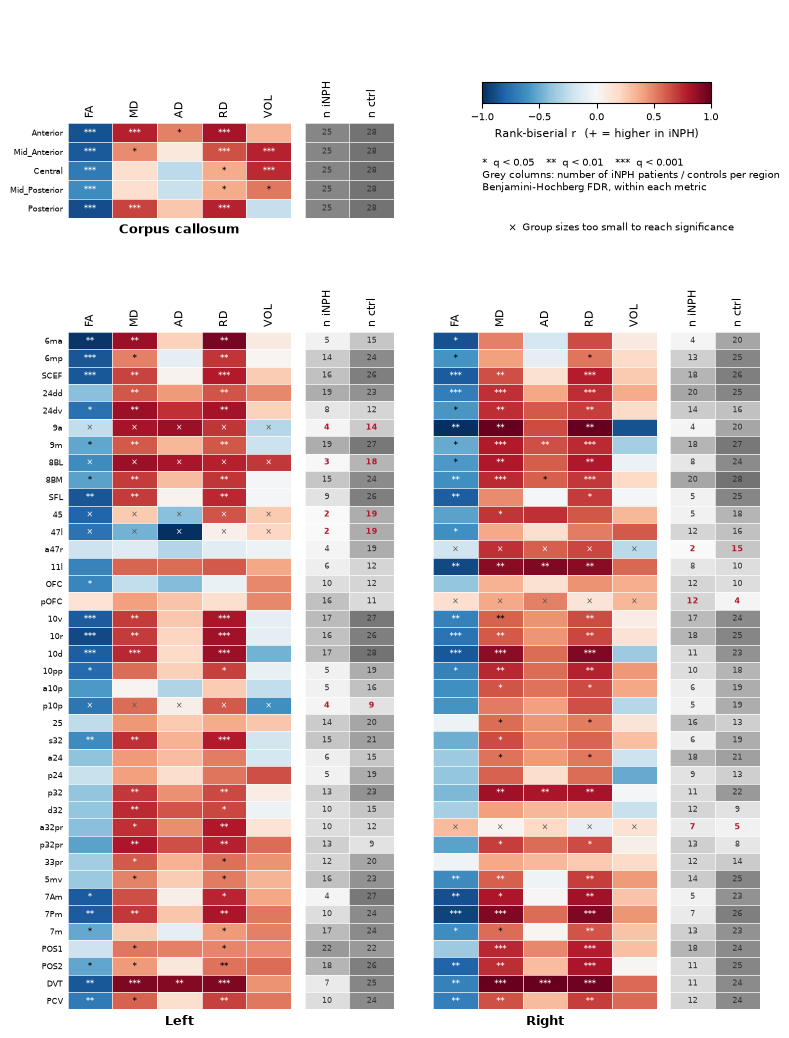

In [83]:
# CELL 6 - RUN IT
results = add_panels(add_status(add_fdr(load_all_metrics())))

print(failed_summary(results))   # no-data and low-n cells per metric

fig = plot_heatmap(
    results,
    **COLORS,                  # colors are set in Cell 1B
    **DISPLAY,                 # what is shown is set in Cell 1C
    title=None,
    save_as="heatmap.png",
)
plt.show()

# Full table for the supplementary material (raw p, q, effect size, plus any extra columns):
results.to_csv("results_with_fdr.csv", index=False)